# 04 · Improvements, from the attribution in 03

03 showed: the beta hedge works; the price loss is all coin-specific; only **coins with extreme
funding** (|forecast| > 300% APY) make money; the ~66 alt shorts held for their beta lose ~47%
on price; a few squeeze days make the total. Steps, each building on the last, chosen on
**`ex_best10_%`** - total net without its 10 best days - so a step wins only if it helps beyond
the luckiest days:

1. **Narrow** to what earns; hedge with BTC/ETH instead of alt shorts.
2. **Tails**: per-coin volatility caps, stop-loss / take-profit.
3. **Drift**: expected return = funding − the price drift of that funding level, learnt on past days.
4. **Position size**: a smaller single-coin cap, chosen on drawdown.
5. **Walk-forward** over the candidates.
6. By year and by coin.

In [1]:
# run from the project root (works from research/ or any subfolder); the strategy package is
# in src/, the data download and plot style in research/lib
import os, sys
while not os.path.isdir("config") and os.path.dirname(os.getcwd()) != os.getcwd():
    os.chdir("..")
sys.path[:0] = [os.path.abspath("src"), os.path.abspath("research/lib")]

In [2]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from betafunding import *
from plotstyle import *
apply()
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
cfg = load_config()                     # the final strategy
SPEC = override(cfg, ORIGINAL_SPEC)     # the design as first specified
panel = load_panel(**cfg["data"])
BM = cfg["benchmarks"]
START = cfg["backtest"]["start"]

base = SPEC
COLS = ["net_apy_%", "funding_apy_%", "price_apy_%", "cost_apy_%", "sharpe", "sortino", "composite",
        "ex_best10_%", "median_month_%", "monthly_win_%", "max_dd_%", "max_dd_compound_%", "worst_day_%",
        "cvar95_%", "avg_gross", "avg_n_long", "avg_n_short", "eff_n", "hold_days", "expost_beta_BTC", "expost_beta_ETH"]
SIG_KEYS = ("beta", "risk.min_dollar_volume", "risk.volume_days", "trade_benchmarks", "funding.forecast",
            "funding.drift_adjust", "funding.drift_prior")
_sigs, RUNS = {}, {}
def _flat(d, pre=""):
    out = {}
    for k, v in d.items():
        out.update(_flat(v, f"{pre}{k}.") if isinstance(v, dict) else {f"{pre}{k}": v})
    return out
def bt(name, cfgx):
    key = repr([(k, v) for k, v in sorted(_flat(cfgx).items()) if k.startswith(SIG_KEYS)])
    s = _sigs.setdefault(key, build_signals(panel, cfgx))
    RUNS[name] = run(panel, s, cfgx, START)
    return summarize(RUNS[name].daily, panel, BM, RUNS[name].weights)
def reuse(name, src, rows):
    RUNS[name] = RUNS[src]
    return rows[src]
def table(rows):
    return pd.DataFrame(rows).T[COLS].astype(float).round(2)
def best(rows):
    return pd.DataFrame(rows).T["ex_best10_%"].astype(float).idxmax()
def metric_bars(rows, pick, title, name):
    t = pd.DataFrame(rows).T.astype(float)
    fig, axes = plt.subplots(1, 2, figsize=(13, 0.45 * len(t) + 1.2), sharey=True)
    for ax, col, lab in [(axes[0], "ex_best10_%", "total net without the 10 best days, %"),
                         (axes[1], "max_dd_compound_%", "max drawdown (compound), %")]:
        cols = [SERIES[0] if k == pick else "#b7d3f6" for k in t.index]
        r = ax.barh(t.index, t[col], color=cols, edgecolor=SURFACE, lw=1.5)
        ax.bar_label(r, fmt="%.0f", fontsize=8, color=INK2, padding=2); ax.axvline(0, color=MUTED, lw=0.8)
        ax.set_xlabel(lab); ax.margins(x=0.1)
    axes[0].invert_yaxis()                 # shared y: once, so the first candidate is on top
    axes[1].tick_params(axis="y", left=False)
    axes[0].set_title(f"{title} (pick highlighted)")
    save(fig, name); plt.show()

## Step 1 · Narrow to what earns

step 1 pick: extremes both sides > 300%, BTC/ETH hedge


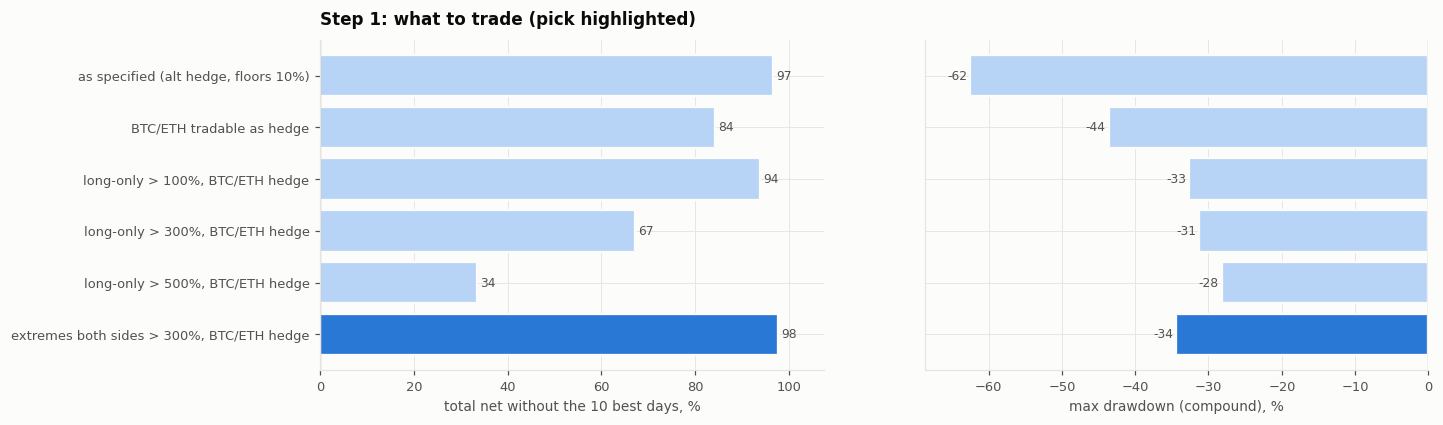

,net_apy_%,funding_apy_%,price_apy_%,cost_apy_%,sharpe,sortino,composite,ex_best10_%,median_month_%,monthly_win_%,max_dd_%,max_dd_compound_%,worst_day_%,cvar95_%,avg_gross,avg_n_long,avg_n_short,eff_n,hold_days,expost_beta_BTC,expost_beta_ETH
"as specified (alt hedge, floors 10%)",114.11,209.89,-85.53,10.25,1.62,2.70,1.97,96.60,4.69,58.06,-85.08,-62.46,-20.75,-6.71,0.98,18.84,21.12,11.87,4.52,-0.10,0.03
BTC/ETH tradable as hedge,109.81,226.58,-105.30,11.47,1.47,2.39,2.08,84.15,4.97,70.97,-48.54,-43.59,-25.05,-7.29,1.52,20.60,25.68,8.61,5.78,-0.14,-0.01
"long-only > 100%, BTC/ETH hedge",108.46,215.91,-99.22,8.23,1.72,2.98,2.55,93.82,4.46,67.74,-38.72,-32.61,-17.99,-5.80,0.87,7.71,1.64,4.30,3.65,-0.07,-0.03
"long-only > 300%, BTC/ETH hedge",97.62,189.30,-83.97,7.71,1.63,2.71,2.37,67.22,2.22,54.84,-36.52,-31.29,-18.31,-5.49,0.56,3.15,1.44,3.05,2.62,-0.04,-0.05
"long-only > 500%, BTC/ETH hedge",81.06,160.41,-72.46,6.89,1.48,2.43,2.19,33.53,0.31,54.84,-31.37,-28.18,-17.56,-5.02,0.42,1.94,1.38,2.59,2.45,-0.02,-0.06
"extremes both sides > 300%, BTC/ETH hedge",108.94,178.27,-60.76,8.57,1.73,2.61,2.36,97.71,2.38,54.84,-41.15,-34.38,-20.39,-6.20,0.58,3.19,1.54,3.06,2.49,-0.07,-0.02


In [3]:
HEDGE = {"trade_benchmarks": True}
LONG_ONLY = lambda floor: {**HEDGE, "funding.min_apy_long": floor, "funding.min_apy_short": 1e9}
step1 = {
    "as specified (alt hedge, floors 10%)": base,
    "BTC/ETH tradable as hedge": override(base, HEDGE),
    "long-only > 100%, BTC/ETH hedge": override(base, LONG_ONLY(100.0)),
    "long-only > 300%, BTC/ETH hedge": override(base, LONG_ONLY(300.0)),
    "long-only > 500%, BTC/ETH hedge": override(base, LONG_ONLY(500.0)),
    "extremes both sides > 300%, BTC/ETH hedge": override(base, {**HEDGE, "funding.min_apy_long": 300.0, "funding.min_apy_short": 300.0}),
}
rows1 = {k: bt(k, c) for k, c in step1.items()}
pick1 = best(rows1); C1 = step1[pick1]
print("step 1 pick:", pick1)
metric_bars(rows1, pick1, "Step 1: what to trade", "step1")
table(rows1)

## Step 2 · Tails: volatility caps, stops

step 2 pick: stop-loss 20%


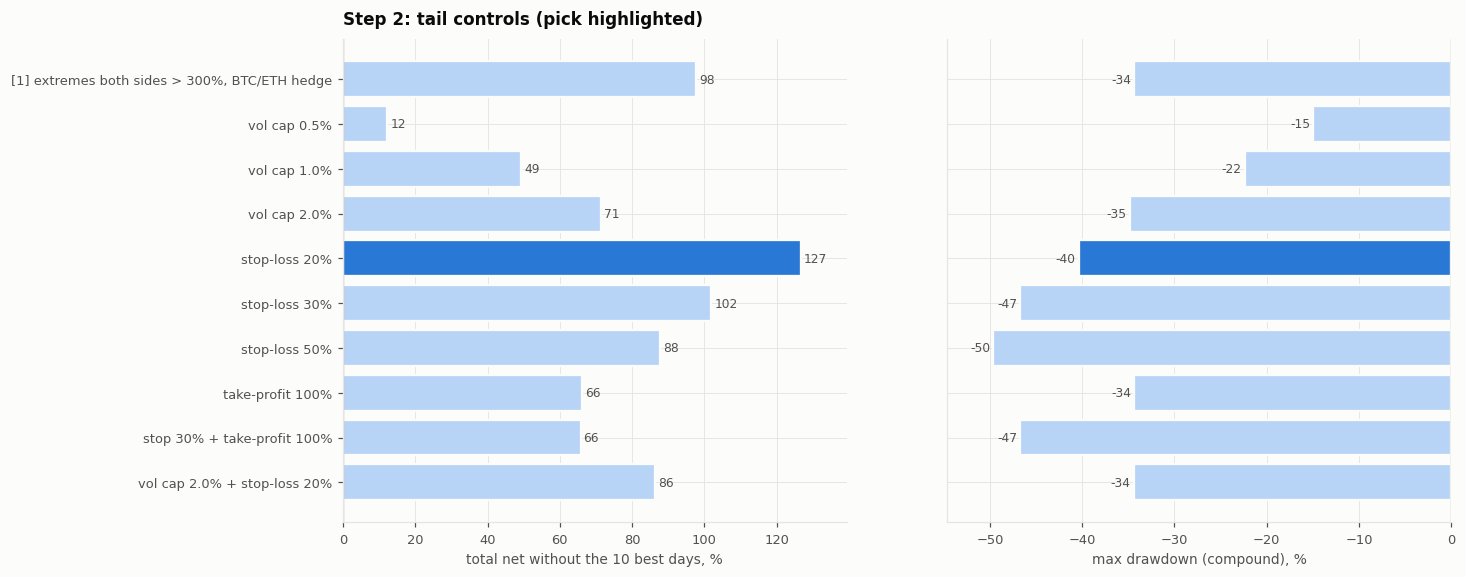

,net_apy_%,funding_apy_%,price_apy_%,cost_apy_%,sharpe,sortino,composite,ex_best10_%,median_month_%,monthly_win_%,max_dd_%,max_dd_compound_%,worst_day_%,cvar95_%,avg_gross,avg_n_long,avg_n_short,eff_n,hold_days,expost_beta_BTC,expost_beta_ETH
"[1] extremes both sides > 300%, BTC/ETH hedge",108.94,178.27,-60.76,8.57,1.73,2.61,2.36,97.71,2.38,54.84,-41.15,-34.38,-20.39,-6.20,0.58,3.19,1.54,3.06,2.49,-0.07,-0.02
vol cap 0.5%,22.12,55.20,-29.85,3.23,1.30,2.04,1.63,12.31,0.95,61.29,-15.81,-14.95,-4.75,-1.75,0.27,3.23,1.56,3.05,2.56,-0.01,-0.02
vol cap 1.0%,53.23,101.60,-42.77,5.61,1.72,2.86,2.30,49.37,1.58,58.06,-25.03,-22.40,-7.67,-3.01,0.43,3.26,1.54,3.05,2.51,-0.01,-0.03
vol cap 2.0%,83.85,150.70,-59.10,7.74,1.68,2.78,2.22,71.32,1.11,58.06,-41.94,-34.85,-11.65,-4.86,0.55,3.24,1.54,3.07,2.51,-0.03,-0.03
stop-loss 20%,114.40,159.82,-36.90,8.51,1.93,2.84,2.47,126.71,2.73,61.29,-45.42,-40.38,-24.48,-5.50,0.54,2.74,1.51,2.90,2.14,-0.04,-0.02
stop-loss 30%,104.58,167.65,-54.46,8.61,1.79,2.64,2.13,101.91,2.73,58.06,-58.24,-46.69,-22.91,-5.62,0.56,2.90,1.52,2.97,2.28,-0.03,-0.04
stop-loss 50%,98.08,173.60,-66.89,8.64,1.63,2.26,1.86,87.71,2.47,58.06,-62.83,-49.64,-23.15,-6.22,0.57,3.06,1.54,3.02,2.41,-0.05,-0.02
take-profit 100%,96.48,170.70,-65.63,8.60,1.59,2.49,2.18,66.09,2.38,54.84,-41.15,-34.38,-20.39,-5.90,0.57,3.09,1.55,3.03,2.39,-0.04,-0.05
stop 30% + take-profit 100%,88.95,160.10,-62.52,8.63,1.60,2.44,1.91,65.74,2.73,58.06,-58.24,-46.69,-22.91,-5.33,0.55,2.81,1.53,2.95,2.20,0.01,-0.07
vol cap 2.0% + stop-loss 20%,87.85,134.54,-39.00,7.69,1.83,2.92,2.36,86.26,2.75,61.29,-41.24,-34.40,-15.98,-4.51,0.51,2.75,1.51,2.92,2.14,-0.02,-0.03


In [4]:
step2 = {f"[1] {pick1}": C1}
for vc in [0.005, 0.01, 0.02]:
    step2[f"vol cap {vc:.1%}"] = override(C1, {"risk.vol_cap": vc})
for sl in [0.2, 0.3, 0.5]:
    step2[f"stop-loss {sl:.0%}"] = override(C1, {"risk.stop_loss": sl})
step2["take-profit 100%"] = override(C1, {"risk.take_profit": 1.0})
step2["stop 30% + take-profit 100%"] = override(C1, {"risk.stop_loss": 0.3, "risk.take_profit": 1.0})
rows2 = {k: (reuse(k, pick1, rows1) if k.startswith("[1]") else bt(k, c)) for k, c in step2.items()}
vc_best = max([k for k in rows2 if k.startswith("vol cap")], key=lambda k: rows2[k]["ex_best10_%"])
st_best = max([k for k in rows2 if "stop" in k or "take" in k], key=lambda k: rows2[k]["ex_best10_%"])
combo = override(step2[st_best], {"risk.vol_cap": step2[vc_best]["risk"]["vol_cap"]})
rows2[f"{vc_best} + {st_best}"] = bt(f"{vc_best} + {st_best}", combo); step2[f"{vc_best} + {st_best}"] = combo
pick2 = best(rows2); C2 = step2[pick2]
print("step 2 pick:", pick2)
metric_bars(rows2, pick2, "Step 2: tail controls", "step2")
table(rows2)

## Step 3 · Drift-adjusted expected return

Per funding-forecast bucket, the mean next-day BTC/ETH-hedged return of a long over all past
tradable coin-days (expanding, shrunk toward 0). First, what it learns:

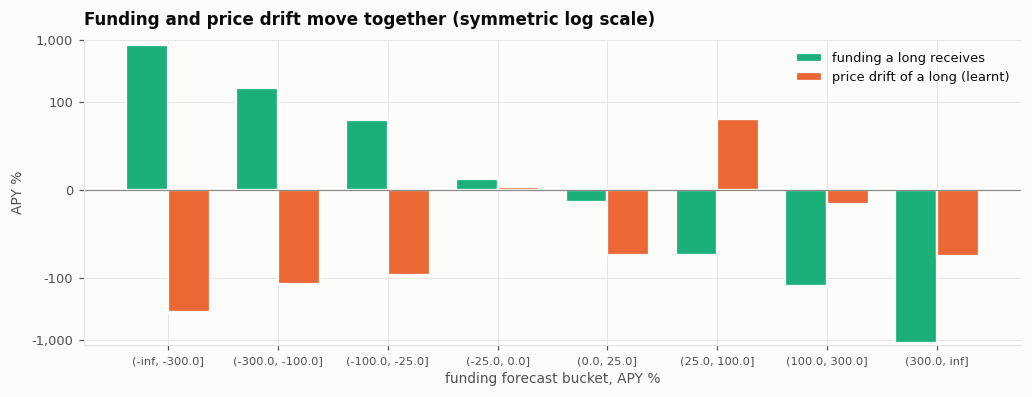

,coin_days,funding_APY_%,drift_APY_%,long_net_APY_%
"(-inf, -300.0]",2939,-849.1,-352.9,496.2
"(-300.0, -100.0]",5928,-172.3,-123.8,48.5
"(-100.0, -25.0]",11620,-51.9,-90.1,-38.3
"(-25.0, 0.0]",24519,-8.2,2.6,10.8
"(0.0, 25.0]",83999,8.6,-46.8,-55.4
"(25.0, 100.0]",15589,46.8,55.0,8.3
"(100.0, 300.0]",1107,134.0,-9.7,-143.6
"(300.0, inf]",95,1110.0,-47.8,-1157.8


In [5]:
sd = build_signals(panel, override(base, {"funding.drift_adjust": True}))
x = (sd.f_hat * APY).where(sd.eligible)
b = pd.cut(x.stack(), DRIFT_EDGES)
learned = pd.DataFrame({"coin_days": b.value_counts().sort_index(),
                        "funding_APY_%": x.stack().groupby(b).mean(),
                        "drift_APY_%": (sd.drift * APY).where(sd.eligible).stack().groupby(b).mean()})
learned["long_net_APY_%"] = learned["drift_APY_%"] - learned["funding_APY_%"]
lab = [str(i) for i in learned.index]
fig, ax = plt.subplots(figsize=(11, 3.6)); xx = np.arange(len(lab)); w = 0.38
ax.bar(xx - w/2, -learned["funding_APY_%"], w, color=PNL["funding"], edgecolor=SURFACE, lw=1.5, label="funding a long receives")
ax.bar(xx + w/2, learned["drift_APY_%"], w, color=PNL["price"], edgecolor=SURFACE, lw=1.5, label="price drift of a long (learnt)")
zero(ax); ax.set_xticks(xx, lab, fontsize=7.5); ax.set_xlabel("funding forecast bucket, APY %"); ax.set_ylabel("APY %")
ax.set_yscale("symlog", linthresh=50)
ticks = [-1000, -100, 0, 100, 1000]; ax.set_yticks(ticks, [f"{t:,}" for t in ticks]); ax.minorticks_off()
ax.set_title("Funding and price drift move together (symmetric log scale)"); ax.legend(loc="upper right")
save(fig, "drift_model"); plt.show()
learned.round(1)

In [6]:
step3 = {f"[2] {pick2}": C2,
         "[2] + drift adjust": override(C2, {"funding.drift_adjust": True}),
         "as specified + drift adjust": override(base, {"funding.drift_adjust": True})}
rows3 = {k: (reuse(k, pick2, rows2) if k.startswith("[2] ") and "drift" not in k else bt(k, c)) for k, c in step3.items()}
pick3 = best(rows3); C3 = step3[pick3]
print("step 3 pick:", pick3)
table(rows3)

step 3 pick: [2] stop-loss 20%


,net_apy_%,funding_apy_%,price_apy_%,cost_apy_%,sharpe,sortino,composite,ex_best10_%,median_month_%,monthly_win_%,max_dd_%,max_dd_compound_%,worst_day_%,cvar95_%,avg_gross,avg_n_long,avg_n_short,eff_n,hold_days,expost_beta_BTC,expost_beta_ETH
[2] stop-loss 20%,114.40,159.82,-36.90,8.51,1.93,2.84,2.47,126.71,2.73,61.29,-45.42,-40.38,-24.48,-5.50,0.54,2.74,1.51,2.90,2.14,-0.04,-0.02
[2] + drift adjust,72.49,101.13,-21.71,6.93,1.50,2.07,1.71,43.04,-0.17,48.39,-50.32,-40.52,-23.29,-4.63,0.33,1.30,1.57,2.39,1.92,-0.01,-0.04
as specified + drift adjust,19.00,161.93,-125.00,17.93,0.29,0.43,0.31,-124.09,2.48,58.06,-127.26,-75.34,-23.61,-7.02,1.57,15.20,45.49,15.44,3.67,-0.03,-0.11


## Step 4 · Position size

The picks so far hold ~4 coins with up to 40% in one; a single coin's jump (a +57% squeeze on a
39% short) sets the drawdown. A smaller single-coin cap shrinks those positions - few coins pass
the 300% floor, so it sizes the book down rather than spreading it. Chosen on drawdown, not on
`ex_best10_%`: the cap that halves the drawdown while keeping Sharpe within ~0.1.

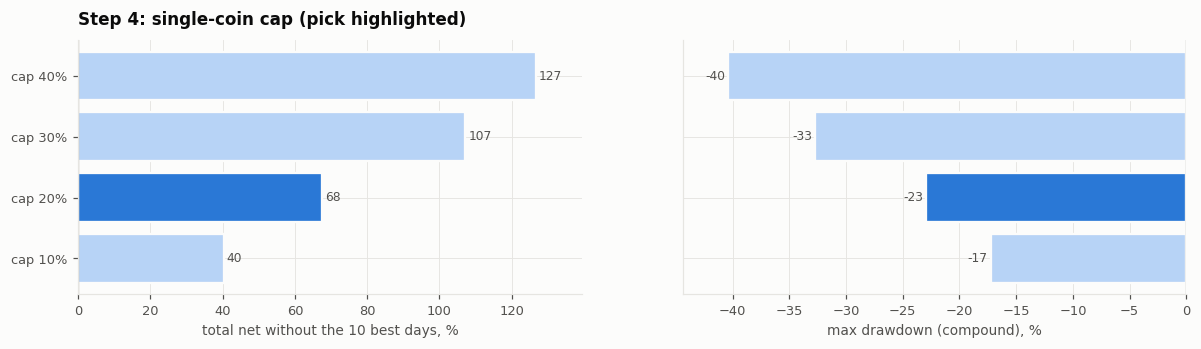

,net_apy_%,funding_apy_%,price_apy_%,cost_apy_%,sharpe,sortino,composite,ex_best10_%,median_month_%,monthly_win_%,max_dd_%,max_dd_compound_%,worst_day_%,cvar95_%,avg_gross,avg_n_long,avg_n_short,eff_n,hold_days,expost_beta_BTC,expost_beta_ETH
cap 40%,114.40,159.82,-36.90,8.51,1.93,2.84,2.47,126.71,2.73,61.29,-45.42,-40.38,-24.48,-5.50,0.54,2.74,1.51,2.90,2.14,-0.04,-0.02
cap 30%,102.32,138.85,-29.56,6.96,1.94,2.86,2.58,107.18,2.47,58.06,-35.63,-32.74,-21.92,-4.88,0.46,2.75,1.50,2.98,2.14,-0.04,-0.01
cap 20%,80.59,110.15,-24.53,5.04,1.87,3.16,2.86,67.51,1.29,64.52,-23.32,-22.95,-13.21,-3.76,0.36,2.65,1.51,3.09,2.14,-0.04,-0.01
cap 10%,52.52,71.31,-16.01,2.78,1.86,3.24,2.72,40.26,1.10,58.06,-18.10,-17.23,-8.52,-2.39,0.21,2.63,1.53,3.24,2.12,-0.02,0.00


In [7]:
step4 = {f"cap {c:.0%}": override(C3, {"risk.max_weight": c}) for c in (0.40, 0.30, 0.20, 0.10)}
rows4 = {k: bt(k, c) for k, c in step4.items()}
pick4 = "cap 20%"; C4 = step4[pick4]
metric_bars(rows4, pick4, "Step 4: single-coin cap", "step4")
table(rows4)

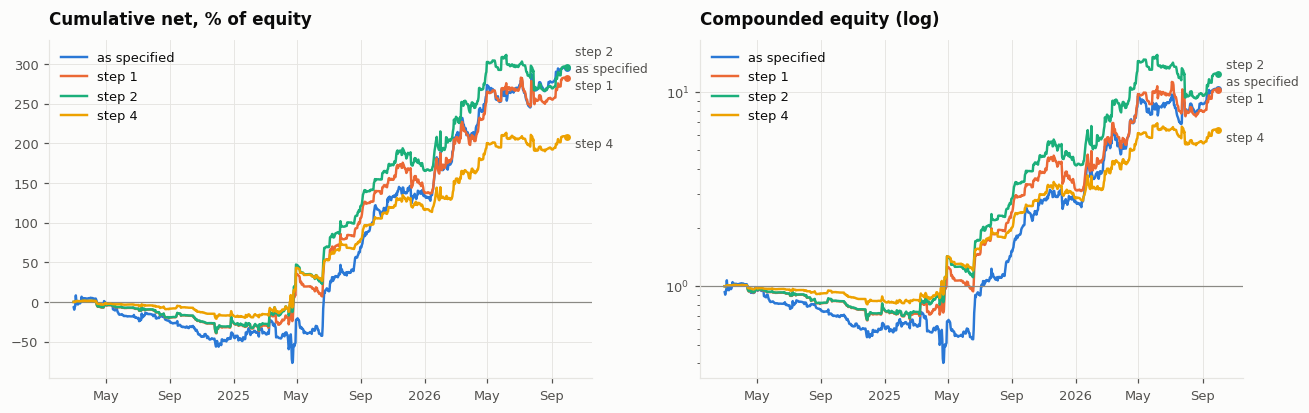

,net_apy_%,funding_apy_%,price_apy_%,cost_apy_%,sharpe,sortino,composite,ex_best10_%,median_month_%,monthly_win_%,max_dd_%,max_dd_compound_%,worst_day_%,cvar95_%,avg_gross,avg_n_long,avg_n_short,eff_n,hold_days,expost_beta_BTC,expost_beta_ETH
"as specified: as specified (alt hedge, floors 10%)",114.11,209.89,-85.53,10.25,1.62,2.70,1.97,96.60,4.69,58.06,-85.08,-62.46,-20.75,-6.71,0.98,18.84,21.12,11.87,4.52,-0.10,0.03
"step 1: extremes both sides > 300%, BTC/ETH hedge",108.94,178.27,-60.76,8.57,1.73,2.61,2.36,97.71,2.38,54.84,-41.15,-34.38,-20.39,-6.20,0.58,3.19,1.54,3.06,2.49,-0.07,-0.02
step 2: stop-loss 20%,114.40,159.82,-36.90,8.51,1.93,2.84,2.47,126.71,2.73,61.29,-45.42,-40.38,-24.48,-5.50,0.54,2.74,1.51,2.90,2.14,-0.04,-0.02
step 4: cap 20%,80.59,110.15,-24.53,5.04,1.87,3.16,2.86,67.51,1.29,64.52,-23.32,-22.95,-13.21,-3.76,0.36,2.65,1.51,3.09,2.14,-0.04,-0.01


In [8]:
show = {"as specified": "as specified (alt hedge, floors 10%)", "step 1": pick1, "step 2": pick2, "step 4": pick4}
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for (lab, k), c in zip(show.items(), SERIES):
    d = RUNS[k].daily
    y = d["net"].cumsum() * 100; axes[0].plot(y.index, y, color=c, label=lab); end_label(axes[0], y, lab, c)
    e = (1 + d["net"]).cumprod(); axes[1].semilogy(e.index, e, color=c, label=lab); end_label(axes[1], e, lab, c)
zero(axes[0]); axes[0].set_title("Cumulative net, % of equity"); axes[0].legend(loc="upper left")
axes[1].axhline(1, color=MUTED, lw=0.8); axes[1].set_title("Compounded equity (log)"); axes[1].legend(loc="upper left")
save(fig, "steps_equity"); plt.show()
table({f"{lab}: {k}": summarize(RUNS[k].daily, panel, BM, RUNS[k].weights) for lab, k in show.items()})

## Step 5 · Walk-forward

Candidates: the book as specified and the pick of each step. Per 60-day block, the candidate with
the best composite score (0.4 Sortino + 0.3 Sharpe + 0.3 Calmar) over all earlier days is traded,
book carried over. Only test days are reported.

In [9]:
def as_overrides(c):
    flat, flat0 = _flat(c), _flat(base)
    return {k: v for k, v in flat.items() if flat0.get(k) != v}
cands = {"as specified": {}, "step 1": as_overrides(C1), "step 2": as_overrides(C2), "step 3": as_overrides(C3),
         "step 4": as_overrides(C4), "as specified + drift": {"funding.drift_adjust": True}}
cands = {k: v for k, v in cands.items() if v not in [cands[j] for j in list(cands)[:list(cands).index(k)]]}
for k, v in cands.items(): print(f"{k:22s}", v)
wf = walk_forward(panel, override(base, {"walkforward.score": "composite"}), points=cands, verbose=False)
f = wf.folds.copy()
print(len(f), "blocks;", len(wf.daily), "OOS days | total OOS net %:", round(f["test_net_%"].sum(), 2),
      "| without the best block:", round(f["test_net_%"].sum() - f["test_net_%"].max(), 2))
f.round(2)

as specified           {}
step 1                 {'trade_benchmarks': True, 'funding.min_apy_long': 300.0, 'funding.min_apy_short': 300.0}
step 2                 {'trade_benchmarks': True, 'funding.min_apy_long': 300.0, 'funding.min_apy_short': 300.0, 'risk.stop_loss': 0.2}
step 4                 {'trade_benchmarks': True, 'funding.min_apy_long': 300.0, 'funding.min_apy_short': 300.0, 'risk.max_weight': 0.2, 'risk.stop_loss': 0.2}
as specified + drift   {'funding.drift_adjust': True}


14 blocks; 824 OOS days | total OOS net %: 177.04 | without the best block: 120.79


,train,test,chosen,train_composite,test_composite,test_net_%,test_funding_%
0,2024-03-01 → 2024-06-28,2024-06-29 → 2024-08-27,as specified,-1.89,-0.36,-0.98,10.58
1,2024-03-01 → 2024-08-27,2024-08-28 → 2024-10-26,as specified,-1.56,-5.41,-17.70,4.98
2,2024-03-01 → 2024-10-26,2024-10-27 → 2024-12-25,as specified,-1.95,-1.38,-4.98,9.02
3,2024-03-01 → 2024-12-25,2024-12-26 → 2025-02-23,as specified,-1.68,4.01,13.34,31.15
4,2024-03-01 → 2025-02-23,2025-02-24 → 2025-04-24,as specified,-0.96,-3.45,-41.93,40.40
5,2024-03-01 → 2025-04-24,2025-04-25 → 2025-06-23,step 4,-0.20,15.90,56.25,22.42
6,2024-03-01 → 2025-06-23,2025-06-24 → 2025-08-22,step 4,1.72,7.41,20.00,13.19
7,2024-03-01 → 2025-08-22,2025-08-23 → 2025-10-21,step 2,2.16,50.47,53.99,20.28
8,2024-03-01 → 2025-10-21,2025-10-22 → 2025-12-20,step 4,2.99,3.28,13.79,34.86
9,2024-03-01 → 2025-12-20,2025-12-21 → 2026-02-18,step 4,2.89,0.96,4.81,47.07


,net_apy_%,funding_apy_%,price_apy_%,cost_apy_%,sharpe,sortino,composite,ex_best10_%,median_month_%,monthly_win_%,max_dd_%,max_dd_compound_%,worst_day_%,cvar95_%,avg_gross,avg_n_long,avg_n_short,eff_n,hold_days,expost_beta_BTC,expost_beta_ETH
walk-forward (OOS),78.42,148.53,-62.31,7.80,1.45,2.13,1.65,32.77,4.69,64.29,-64.22,-52.85,-20.75,-5.48,0.63,7.55,10.24,6.27,3.44,-0.03,-0.01
"as specified, same days",139.23,234.85,-85.01,10.61,1.88,3.17,2.50,116.54,5.37,60.71,-63.24,-52.38,-20.75,-6.88,1.03,20.53,19.23,11.68,NaN,-0.02,0.00
"final (step 4), same days",94.05,125.23,-25.72,5.45,2.04,3.51,3.23,71.41,2.26,67.86,-23.32,-22.95,-13.21,-4.01,0.39,2.98,1.47,3.23,NaN,-0.04,-0.01


chosen per block:
chosen
step 4          8
as specified    5
step 2          1


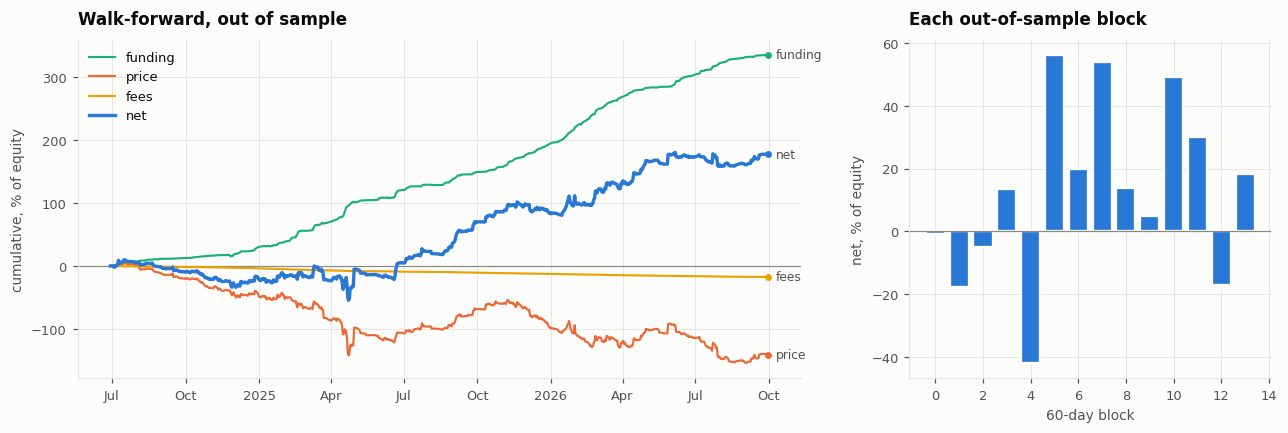

In [10]:
oos = wf.daily.index
out = {"walk-forward (OOS)": summarize(wf.daily, panel, BM, wf.weights),
       "as specified, same days": summarize(RUNS["as specified (alt hedge, floors 10%)"].daily.loc[oos], panel, BM),
       "final (step 4), same days": summarize(RUNS[pick4].daily.loc[oos], panel, BM)}
display(pd.DataFrame(out).T[COLS].astype(float).round(2))
print("chosen per block:"); print(f["chosen"].value_counts().to_string())
fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [2, 1]})
pnl_lines(axes[0], wf.daily.rename(columns={"cost": "fee"}), title="Walk-forward, out of sample")
r = axes[1].bar(range(len(f)), f["test_net_%"], color=PNL["net"], edgecolor=SURFACE, lw=1.5)
zero(axes[1]); axes[1].set_xlabel("60-day block"); axes[1].set_ylabel("net, % of equity"); axes[1].set_title("Each out-of-sample block")
save(fig, "walkforward"); plt.show()

## Step 6 · By year and by coin

(How the result changes with the liquidity floor is the extension notebook, 06.)

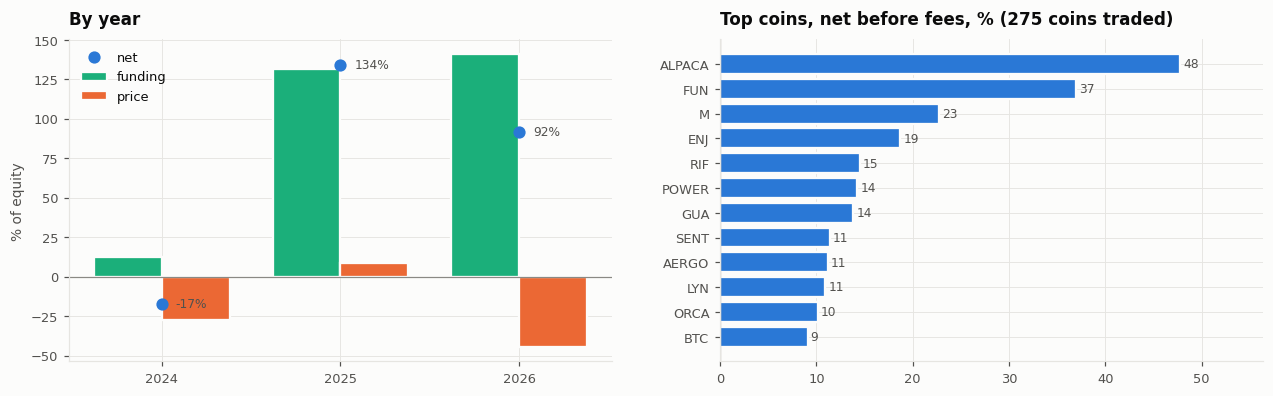

total (before fees) 221% | without best 1 / 3 / 5 / 10 coins: [np.float64(174.0), np.float64(114.0), np.float64(81.0), np.float64(19.0)]


,funding,price,cost,net
date,,,,
2024,12.7,-27.7,2.3,-17.4
2025,131.3,8.7,5.7,134.3
2026,140.9,-44.4,5.0,91.6


In [11]:
d = RUNS[pick4].daily
yr = d[["funding", "price", "cost", "net"]].groupby(d.index.year).sum().mul(100)
W = RUNS[pick4].weights
R = panel.ret.reindex(index=W.index, columns=W.columns).fillna(0)
Fu = panel.funding.reindex(index=W.index, columns=W.columns).fillna(0)
by_coin = ((W * R) - (W * Fu)).sum().sort_values(ascending=False) * 100
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
xx = np.arange(len(yr)); w = 0.38
axes[0].bar(xx - w/2, yr["funding"], w, color=PNL["funding"], edgecolor=SURFACE, lw=1.5, label="funding")
axes[0].bar(xx + w/2, yr["price"], w, color=PNL["price"], edgecolor=SURFACE, lw=1.5, label="price")
axes[0].plot(xx, yr["net"], "o", color=PNL["net"], ms=7, label="net")
for i, v in enumerate(yr["net"]): axes[0].annotate(f"{v:.0f}%", (i, v), xytext=(9, 0), textcoords="offset points", fontsize=8, color=INK2, va="center")
zero(axes[0]); axes[0].set_xticks(xx, yr.index); axes[0].set_ylabel("% of equity"); axes[0].set_title("By year"); axes[0].legend(loc="upper left")
bars(axes[1], by_coin.head(12)[::-1], horizontal=True, fmt="{:.0f}")
axes[1].set_title(f"Top coins, net before fees, % ({(W != 0).any().sum()} coins traded)")
save(fig, "by_year_and_coin"); plt.show()
print(f"total (before fees) {by_coin.sum():.0f}% | without best 1 / 3 / 5 / 10 coins:",
      [round(by_coin.iloc[n:].sum(), 0) for n in (1, 3, 5, 10)])
yr.round(1)

## Findings ($20m floor)

| | net APY | Sharpe | without best 10 days | median month | max DD (compound) | worst day |
|---|---|---|---|---|---|---|
| as specified | +114% | 1.62 | +97% | +4.7% | −62% | −21% |
| step 1: extremes both sides > 300%, BTC/ETH hedge | +109% | 1.73 | +98% | +2.4% | −34% | −20% |
| step 2: + 20% stop-loss | +114% | 1.93 | +127% | +2.7% | −40% | −24% |
| step 3: + drift adjustment | +72% | 1.50 | +43% | −0.2% | −41% | |
| **step 4: + 20% single-coin cap (final)** | **+81%** | **1.87** | **+68%** | +1.3% | **−23%** | **−13%** |

- Step 1 drops the alt-short ballast and the mid-funding coins: same return, drawdown roughly halved.
- Step 2: a 20% stop is the best tail control on returns; vol caps cut drawdown further but cost more return.
- Step 3 hurts (the learnt drift overlaps the funding signal) and is not used.
- **Step 4**: the drawdown was single-coin jumps on 30–40% positions (a +57% squeeze on a 39% short alone cost 22%). A 20% cap halves the drawdown and the worst day for ~0.06 of Sharpe. Few coins pass the 300% floor, so the cap sizes the book down rather than spreading it.
- **Walk-forward** (14 blocks, 824 OOS days): **+78% APY, Sharpe 1.45**, compound max DD −53%, positive in 9 of 14 blocks. The selector keeps the original book for the first five blocks (Jun 2024 – Apr 2025) - the improvements had no track record yet - and that stretch sets the drawdown (one block −42%). From May 2025 it picks step 4 (or step 2 once): 8 of 9 blocks positive. The final book alone on the same 824 days: Sharpe 2.04, max DD −23%.
- By year (final book): 2024 −17%, 2025 +134%, 2026 +92%. The best 10 of the coins traded make most of the total.